# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('emergency_events.csv')

In [3]:
df

,event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,outcome
0,EMG_000001,2023-01-01 06:31:00,D11,Medical Emergency,Medium,23.238000,1,0,0,0,Resolved On-Site
1,EMG_000002,2023-01-01 07:01:00,D05,Medical Emergency,Low,17.542814,1,0,0,0,Resolved On-Site
2,EMG_000003,2023-01-01 17:54:00,D07,Traffic Accident,High,13.675920,1,1,0,1,Transported to Hospital
3,EMG_000004,2023-01-01 19:09:00,D07,Public Safety Incident,Low,20.669389,0,0,0,0,Resolved On-Site
4,EMG_000005,2023-01-01 21:51:00,D09,Medical Emergency,Low,19.989403,1,0,0,0,Transported to Hospital
...,...,...,...,...,...,...,...,...,...,...,...
12923,EMG_012924,2025-12-31 05:34:00,D01,Medical Emergency,Medium,11.890397,1,0,0,0,Transported to Hospital
12924,EMG_012925,2025-12-31 10:59:00,D15,Medical Emergency,Medium,17.867131,1,0,0,0,Resolved On-Site
12925,EMG_012926,2025-12-31 16:19:00,D02,Medical Emergency,Low,27.161067,1,0,0,0,Resolved On-Site
12926,EMG_012927,2025-12-31 16:45:00,D16,Medical Emergency,Critical,11.270792,1,1,0,0,Resolved On-Site


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12928 entries, 0 to 12927
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   event_id                     12928 non-null  str    
 1   timestamp                    12928 non-null  str    
 2   district_id                  12928 non-null  str    
 3   emergency_type               12928 non-null  str    
 4   severity_level               12928 non-null  str    
 5   response_time_minutes        12928 non-null  float64
 6   ambulance_required           12928 non-null  int64  
 7   hospital_transport_required  12928 non-null  int64  
 8   weather_related_flag         12928 non-null  int64  
 9   traffic_related_flag         12928 non-null  int64  
 10  outcome                      12928 non-null  str    
dtypes: float64(1), int64(4), str(6)
memory usage: 2.0 MB


### Converting timestamps to datetime

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

### Checking for duplicated event IDs

In [6]:
# Checking for duplicated primary key
df['event_id'].duplicated().sum()

np.int64(0)

### Sorting data by districts then timestamps

In [7]:
df = df.sort_values(['district_id', 'timestamp']).reset_index(drop=True)

### Understanding columns + feature engineering (if needed)

In [8]:
df.describe()

,timestamp,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag
count,12928,12928.000000,12928.000000,12928.000000,12928.000000,12928.000000
mean,2024-07-06 11:38:09.509591,22.031028,0.724165,0.146194,0.070699,0.354425
min,2023-01-01 06:31:00,2.000000,0.000000,0.000000,0.000000,0.000000
25%,2023-09-27 04:56:00,15.550395,0.000000,0.000000,0.000000,0.000000
50%,2024-06-28 05:16:00,20.108822,1.000000,0.000000,0.000000,0.000000
75%,2025-04-13 16:09:45,26.948931,1.000000,0.000000,0.000000,1.000000
max,2025-12-31 16:59:00,54.691975,1.000000,1.000000,1.000000,1.000000
std,NaN,9.165784,0.446952,0.353315,0.256332,0.478357


In [9]:
df['emergency_type'].unique()

<ArrowStringArray>
[      'Traffic Accident',                   'Fire', 'Public Safety Incident',
      'Medical Emergency', 'Infrastructure Failure',      'Weather Emergency']
Length: 6, dtype: str

In [10]:
df['severity_level'].unique()

<ArrowStringArray>
['Medium', 'Low', 'Critical', 'High']
Length: 4, dtype: str

In [11]:
df['severity_level'].value_counts()

severity_level
Medium      5239
Low         5055
High        1985
Critical     649
Name: count, dtype: int64

In [12]:
df['outcome'].unique()

<ArrowStringArray>
['Transported to Hospital', 'Resolved On-Site', 'Referred to Other Agency']
Length: 3, dtype: str

In [13]:
df[(df['hospital_transport_required'] == 1) & (df['outcome'] != 'Transported to Hospital')]
# Needed to go to hospital but didn't

,event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,outcome
13,EMG_000148,2023-01-15 14:51:00,D01,Traffic Accident,High,9.976415,1,1,0,1,Resolved On-Site
22,EMG_000303,2023-02-01 19:39:00,D01,Medical Emergency,High,24.714616,1,1,0,0,Resolved On-Site
24,EMG_000323,2023-02-03 12:10:00,D01,Traffic Accident,Critical,14.422589,1,1,0,1,Resolved On-Site
52,EMG_000786,2023-03-10 13:37:00,D01,Medical Emergency,High,16.225096,1,1,0,0,Resolved On-Site
55,EMG_000832,2023-03-14 22:53:00,D01,Medical Emergency,Critical,10.430497,1,1,0,0,Referred to Other Agency
...,...,...,...,...,...,...,...,...,...,...,...
12859,EMG_011631,2025-09-14 20:48:00,D20,Medical Emergency,Critical,7.698799,1,1,0,0,Resolved On-Site
12864,EMG_011748,2025-09-25 09:16:00,D20,Traffic Accident,High,18.928280,1,1,0,1,Resolved On-Site
12918,EMG_012803,2025-12-22 18:55:00,D20,Medical Emergency,High,18.836818,1,1,0,0,Resolved On-Site
12922,EMG_012894,2025-12-28 13:13:00,D20,Medical Emergency,High,13.773260,1,1,0,0,Resolved On-Site


In [14]:
df[(df['emergency_type'] == 'Weather Emergency') & (df['weather_related_flag'] == 0)]

,event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,outcome


In [15]:
df[(df['emergency_type'] == 'Traffic Accident') & (df['traffic_related_flag'] == 0)]

,event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,outcome


In [16]:
df[(df['traffic_related_flag'] == 1) & (df['weather_related_flag'] == 1)]

,event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,outcome


## Checking nulls

In [17]:
df.isnull().sum()

event_id                       0
timestamp                      0
district_id                    0
emergency_type                 0
severity_level                 0
response_time_minutes          0
ambulance_required             0
hospital_transport_required    0
weather_related_flag           0
traffic_related_flag           0
outcome                        0
dtype: int64

## Checking outliers

In [18]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return df[(df[column] < lower) | (df[column] > upper)]

for col in ['response_time_minutes']:
    print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

response_time_minutes: 392, mean: 22.03, above upper = 392, below lower = 0


## Validating Outliers

### Response time

In [19]:
find_outliers_iqr(df, 'response_time_minutes')

,event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,outcome
9,EMG_000116,2023-01-12 16:09:00,D01,Weather Emergency,Medium,46.572173,0,0,1,0,Transported to Hospital
33,EMG_000445,2023-02-15 08:20:00,D01,Weather Emergency,Low,51.780867,0,0,1,0,Resolved On-Site
34,EMG_000446,2023-02-15 08:32:00,D01,Traffic Accident,Medium,46.850461,1,0,0,1,Transported to Hospital
38,EMG_000531,2023-02-20 08:00:00,D01,Traffic Accident,Medium,49.487755,1,0,0,1,Resolved On-Site
66,EMG_001045,2023-03-31 22:12:00,D01,Weather Emergency,Low,44.409877,0,0,1,0,Resolved On-Site
...,...,...,...,...,...,...,...,...,...,...,...
12678,EMG_007866,2024-10-25 18:58:00,D20,Infrastructure Failure,Low,44.873936,0,0,0,0,Resolved On-Site
12739,EMG_009047,2025-02-14 08:26:00,D20,Weather Emergency,Low,46.431832,0,0,1,0,Resolved On-Site
12790,EMG_010287,2025-06-05 08:37:00,D20,Medical Emergency,Low,44.283528,1,0,0,0,Transported to Hospital
12808,EMG_010665,2025-06-27 16:02:00,D20,Infrastructure Failure,Low,44.688778,0,0,0,0,Transported to Hospital


# Important KPIs

## Emergency count by type and severity

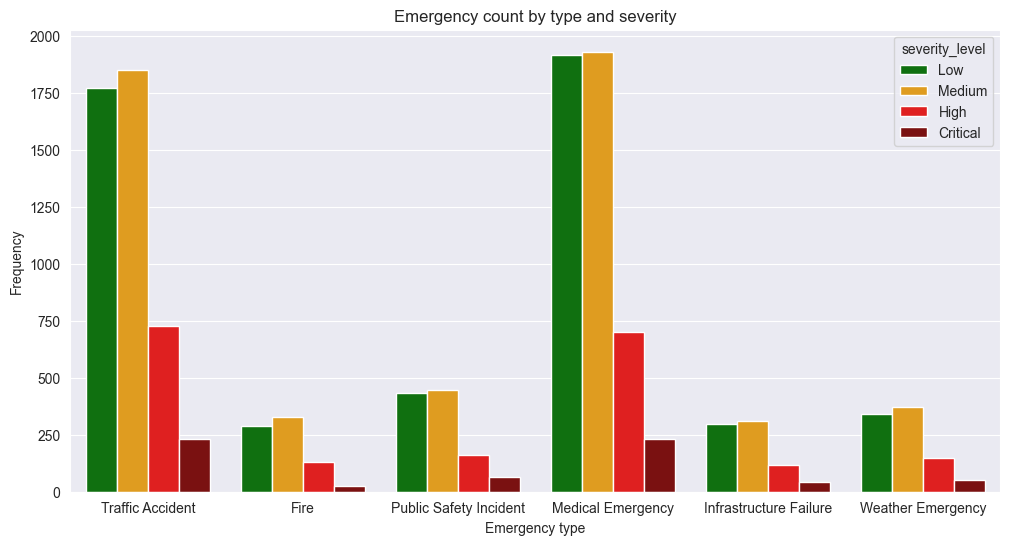

In [20]:
sns.countplot(df, x='emergency_type', hue='severity_level', hue_order=['Low', 'Medium', 'High', 'Critical'], palette=['green', 'orange', 'red', 'darkred'])

plt.xlabel('Emergency type')
plt.ylabel('Frequency')
plt.title('Emergency count by type and severity')

plt.show()

## Average Emergency response time by severity per District

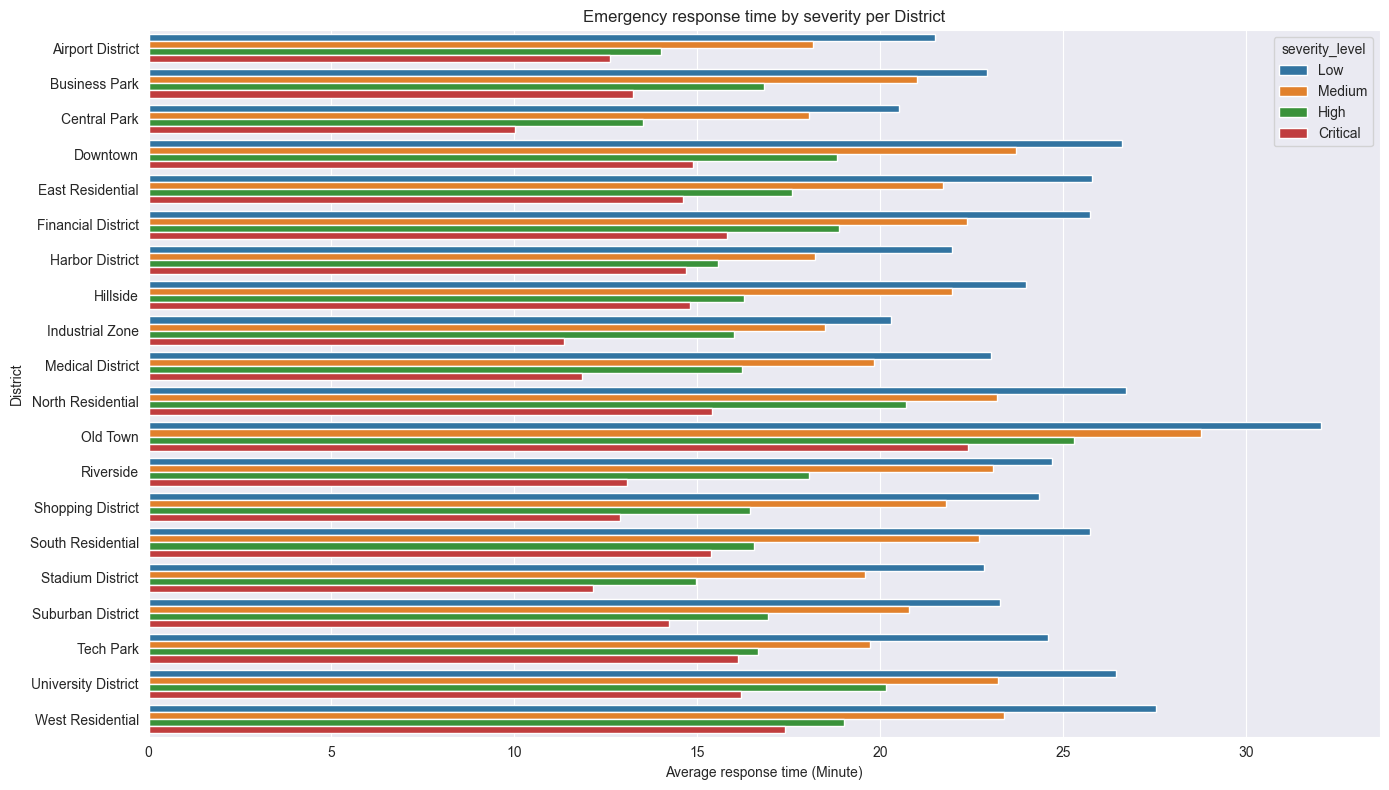

In [21]:
districts = pd.read_csv('districts.csv')
districts_emergency = districts.merge(df, on='district_id')

average_response_time = districts_emergency.groupby(['district_name', 'severity_level']).agg(
    average_response=('response_time_minutes', 'mean')
).reset_index()

plt.figure(figsize=(14,8))
sns.barplot(average_response_time, x='average_response', y='district_name', hue='severity_level', hue_order=['Low', 'Medium', 'High', 'Critical'])

plt.xlabel('Average response time (Minute)')
plt.ylabel('District')
plt.title('Emergency response time by severity per District')

plt.tight_layout()
plt.show()

## Emergencies caused by Weather vs Traffic

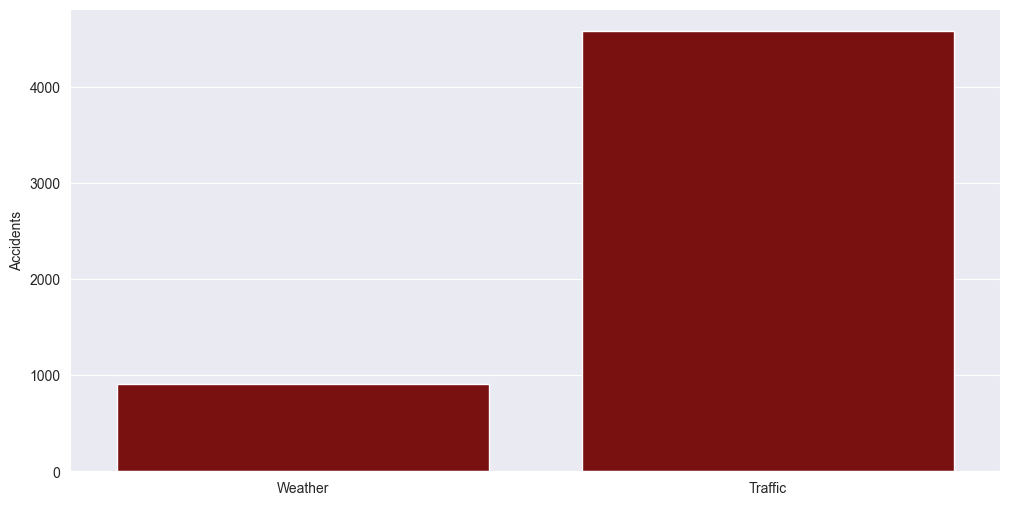

In [22]:
weather_accidents = len(df[df['weather_related_flag'] == 1])
traffic_accidents = len(df[df['traffic_related_flag'] == 1])

sns.barplot(x=['Weather', 'Traffic'], y=[weather_accidents, traffic_accidents], color='darkred')

plt.ylabel('Accidents')
plt.show()

## Emergency outcome distribution

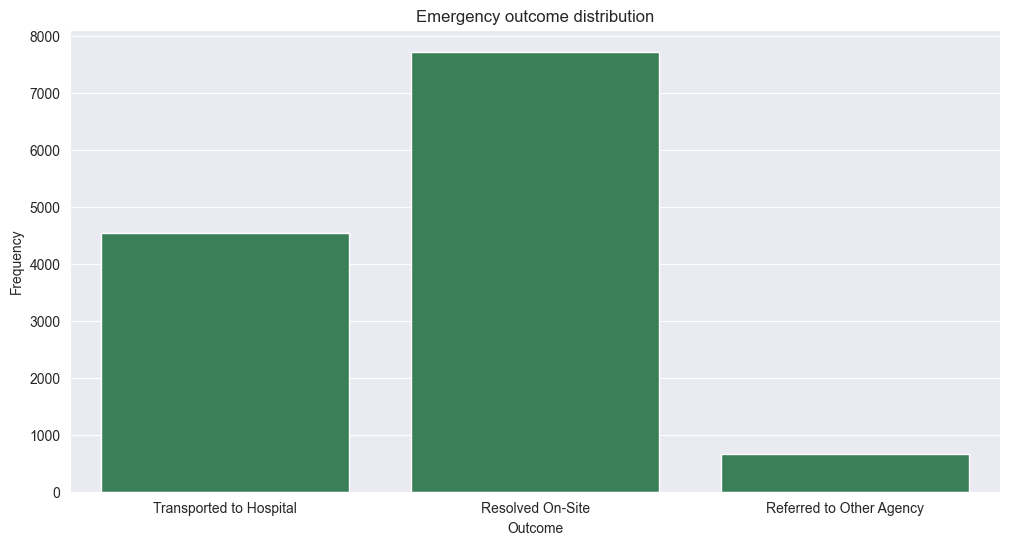

In [23]:
sns.countplot(df, x='outcome', color='seagreen')

plt.xlabel('Outcome')
plt.ylabel('Frequency')
plt.title('Emergency outcome distribution')

plt.show()

# Data Cleaning

In [26]:
cleaned_emergency_events = df

In [25]:
cleaned_emergency_events.to_csv(cleaned_emergency_events.to_csv('data/cleaned_emergency_events.csv', index=False))

',event_id,timestamp,district_id,emergency_type,severity_level,response_time_minutes,ambulance_required,hospital_transport_required,weather_related_flag,traffic_related_flag,outcome\r\n0,EMG_000010,2023-01-02 07:09:00,D01,Traffic Accident,Medium,27.726222783449835,1,0,0,1,Transported to Hospital\r\n1,EMG_000018,2023-01-02 11:57:00,D01,Traffic Accident,Low,23.41347567403945,1,0,0,1,Resolved On-Site\r\n2,EMG_000032,2023-01-03 10:54:00,D01,Fire,Medium,21.251522912383894,0,0,0,0,Transported to Hospital\r\n3,EMG_000036,2023-01-04 11:12:00,D01,Public Safety Incident,Critical,15.29581782667564,0,0,0,0,Resolved On-Site\r\n4,EMG_000052,2023-01-06 05:40:00,D01,Traffic Accident,Low,15.12250128457686,1,0,0,1,Resolved On-Site\r\n5,EMG_000065,2023-01-08 06:09:00,D01,Medical Emergency,High,10.159863906364588,1,1,0,0,Transported to Hospital\r\n6,EMG_000067,2023-01-08 06:11:00,D01,Fire,Low,20.743291426162926,0,0,0,0,Transported to Hospital\r\n7,EMG_000066,2023-01-08 06:14:00,D01,Infrastructure Failure,